STUDENT RECORD SORTING SYSTEM
Dataset Loaded Successfully!
Total Students: 300
Total Columns: 16

       STUDENT RECORD SORTING SYSTEM
1. Display Student Records
2. Sort Using Quick Sort
3. Sort Using Merge Sort
4. Compare Both Algorithms
5. Performance Comparison Graph
6. Exit



Enter your choice (1-6):  1



ORIGINAL STUDENT RECORDS
 student_id             name  age  quiz1_marks  midterm_marks  final_marks  previous_gpa
          1 Kristina Vaughan   19          8.0           30.0         36.5          2.57
          2   Rodney Daniels   21         10.0           25.4         33.0          2.40
          3        Jose Nash   19          7.5           14.4         24.8          2.99
          4    Nicole Martin   21          5.2           17.7         41.0          1.68
          5     Shelby Smith   21          5.9           23.8         31.0          2.53
          6   Austin Griffin   22          5.8            9.4         50.0          1.83
          7   Crystal Jordan   23          7.4           22.0         50.0          2.88
          8 Sandra Patterson   23          6.8           12.8         33.1          3.54
          9    Rachael Miles   23          7.7           16.1         29.8          3.21
         10     Matthew Rice   18          9.1           16.9         45.0          


Enter your choice (1-6):  4



SELECT SORTING FIELD
1. Student ID
2. Student Name
3. Age
4. Quiz Marks
5. Midterm Marks
6. Final Marks
7. Previous GPA


Enter choice (1-7):  4


... (5 outputs left out)

Enter choice (1-7):  4



1. Ascending
2. Descending


Enter choice (1-2):  1



PERFORMANCE COMPARISON
 Records  Quick Sort (ms)  Merge Sort (ms)
      50         0.149291         0.152125
     100         0.313957         0.346863
     150         0.512689         0.565212
     200         0.689613         0.818998
     250         1.118076         1.134684
     300         1.258355         1.146590


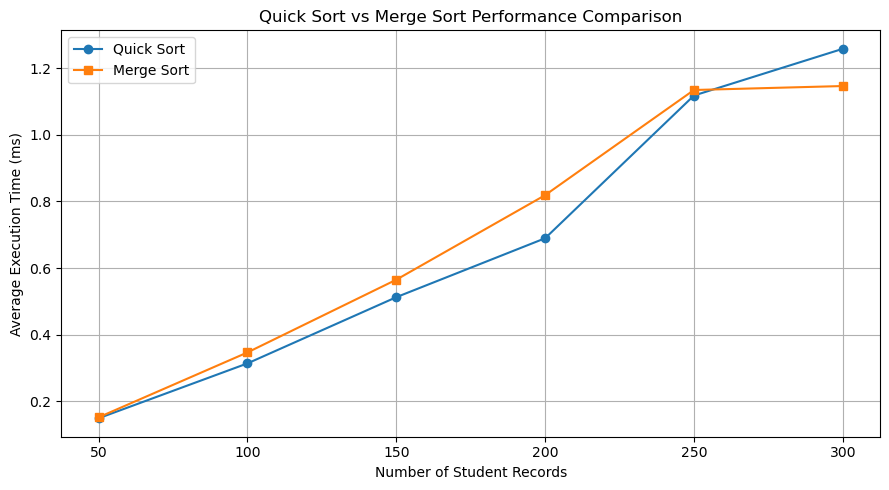


       STUDENT RECORD SORTING SYSTEM
1. Display Student Records
2. Sort Using Quick Sort
3. Sort Using Merge Sort
4. Compare Both Algorithms
5. Performance Comparison Graph
6. Exit



Enter your choice (1-6):  6



Thank you for using Student Record Sorting System!


In [2]:
# import pandas as pd
import time
import matplotlib.pyplot as plt

# ==========================================
# STUDENT RECORD SORTING SYSTEM
# ==========================================

# STEP 1: LOAD DATASET
df = pd.read_csv(r"C:\Users\fizak\Downloads\student_dataset.csv")
records = df.to_dict(orient="records")

print("STUDENT RECORD SORTING SYSTEM")
print("Dataset Loaded Successfully!")
print("Total Students:", len(records))
print("Total Columns:", len(df.columns))


# STEP 2: QUICK SORT ALGORITHM

def quick_sort(arr, field, ascending=True):
    arr = arr.copy()

    def partition(low, high):
        pivot = arr[high][field]
        i = low - 1

        for j in range(low, high):
            value = arr[j][field]

            if isinstance(value, str):
                value = value.lower()
                p = pivot.lower()
            else:
                p = pivot

            condition = value <= p if ascending else value >= p

            if condition:
                i += 1
                arr[i], arr[j] = arr[j], arr[i]

        arr[i + 1], arr[high] = arr[high], arr[i + 1]
        return i + 1

    def sort(low, high):
        if low < high:
            pi = partition(low, high)
            sort(low, pi - 1)
            sort(pi + 1, high)

    sort(0, len(arr) - 1)
    return arr


# STEP 3: MERGE SORT ALGORITHM

def merge_sort(arr, field, ascending=True):

    if len(arr) <= 1:
        return arr.copy()

    mid = len(arr) // 2

    left = merge_sort(arr[:mid], field, ascending)
    right = merge_sort(arr[mid:], field, ascending)

    result = []
    i = 0
    j = 0

    while i < len(left) and j < len(right):

        a = left[i][field]
        b = right[j][field]

        if isinstance(a, str):
            a = a.lower()
            b = b.lower()

        condition = a <= b if ascending else a >= b

        if condition:
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1

    result.extend(left[i:])
    result.extend(right[j:])

    return result


# STEP 4: DISPLAY STUDENT RECORDS

def display_records(data):

    columns = [
        "student_id",
        "name",
        "age",
        "quiz1_marks",
        "midterm_marks",
        "final_marks",
        "previous_gpa"
    ]

    print(pd.DataFrame(data)[columns].head(10).to_string(index=False))
    print("\nShowing first 10 of", len(data), "records")


# STEP 5: SELECT SORTING FIELD

fields = {
    1: "student_id",
    2: "name",
    3: "age",
    4: "quiz1_marks",
    5: "midterm_marks",
    6: "final_marks",
    7: "previous_gpa"
}

def select_field():

    print("\nSELECT SORTING FIELD")
    print("1. Student ID")
    print("2. Student Name")
    print("3. Age")
    print("4. Quiz Marks")
    print("5. Midterm Marks")
    print("6. Final Marks")
    print("7. Previous GPA")

    while True:
        try:
            choice = int(input("Enter choice (1-7): "))
            if choice in fields:
                return fields[choice]
        except ValueError:
            pass
        print("Invalid choice. Try again.")


# STEP 6: SELECT SORTING ORDER

def select_order():

    print("\n1. Ascending")
    print("2. Descending")

    while True:
        choice = input("Enter choice (1-2): ")

        if choice == "1":
            return True
        elif choice == "2":
            return False
        print("Invalid choice.")


# STEP 7: MEASURE EXECUTION TIME

def measure_time(algorithm, data, field, ascending, runs=100):

    total_time = 0
    result = []

    for _ in range(runs):

        start = time.perf_counter()

        result = algorithm(data, field, ascending)

        end = time.perf_counter()

        total_time += end - start

    average_time = (total_time / runs) * 1000

    return result, average_time


# STEP 8: CHECK SORTING CORRECTNESS

def check_correctness(original, sorted_data, field, ascending):

    if len(original) != len(sorted_data):
        return False

    original_ids = sorted(row["student_id"] for row in original)
    result_ids = sorted(row["student_id"] for row in sorted_data)

    if original_ids != result_ids:
        return False

    values = [row[field] for row in sorted_data]

    if values and isinstance(values[0], str):
        values = [v.lower() for v in values]

    for i in range(len(values) - 1):
        if ascending and values[i] > values[i + 1]:
            return False
        if not ascending and values[i] < values[i + 1]:
            return False

    return True


# STEP 9: COMPARE BOTH ALGORITHMS

def compare_algorithms():

    field = select_field()
    ascending = select_order()

    quick_result, quick_time = measure_time(
        quick_sort, records, field, ascending
    )

    merge_result, merge_time = measure_time(
        merge_sort, records, field, ascending
    )

    quick_correct = check_correctness(
        records, quick_result, field, ascending
    )

    merge_correct = check_correctness(
        records, merge_result, field, ascending
    )

    print("\n========== ALGORITHM COMPARISON ==========")

    comparison = pd.DataFrame({
        "Algorithm": ["Quick Sort", "Merge Sort"],
        "Execution Time (ms)": [quick_time, merge_time],
        "Correct": [quick_correct, merge_correct]
    })

    print(comparison.to_string(index=False))

    if quick_time < merge_time:
        print("\nQuick Sort was faster in this test.")
    elif merge_time < quick_time:
        print("\nMerge Sort was faster in this test.")
    else:
        print("\nBoth algorithms took the same time.")


# STEP 10: PERFORMANCE GRAPH

def performance_graph():

    field = select_field()
    ascending = select_order()

    sizes = [50, 100, 150, 200, 250, 300]

    quick_times = []
    merge_times = []
    tested_sizes = []

    for size in sizes:

        if size > len(records):
            continue

        subset = records[:size]

        q_result, q_time = measure_time(
            quick_sort, subset, field, ascending
        )

        m_result, m_time = measure_time(
            merge_sort, subset, field, ascending
        )

        assert check_correctness(subset, q_result, field, ascending)
        assert check_correctness(subset, m_result, field, ascending)

        tested_sizes.append(size)
        quick_times.append(q_time)
        merge_times.append(m_time)

    results = pd.DataFrame({
        "Records": tested_sizes,
        "Quick Sort (ms)": quick_times,
        "Merge Sort (ms)": merge_times
    })

    print("\nPERFORMANCE COMPARISON")
    print(results.to_string(index=False))

    plt.figure(figsize=(9, 5))

    plt.plot(
        tested_sizes,
        quick_times,
        marker="o",
        label="Quick Sort"
    )

    plt.plot(
        tested_sizes,
        merge_times,
        marker="s",
        label="Merge Sort"
    )

    plt.xlabel("Number of Student Records")
    plt.ylabel("Average Execution Time (ms)")
    plt.title("Quick Sort vs Merge Sort Performance Comparison")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# STEP 11: MAIN MENU

while True:

    print("\n==========================================")
    print("       STUDENT RECORD SORTING SYSTEM")
    print("==========================================")

    print("1. Display Student Records")
    print("2. Sort Using Quick Sort")
    print("3. Sort Using Merge Sort")
    print("4. Compare Both Algorithms")
    print("5. Performance Comparison Graph")
    print("6. Exit")

    choice = input("\nEnter your choice (1-6): ")

    if choice == "1":

        print("\nORIGINAL STUDENT RECORDS")
        display_records(records)

    elif choice == "2":

        field = select_field()
        ascending = select_order()

        sorted_data, execution_time = measure_time(
            quick_sort, records, field, ascending
        )

        print("\nSORTED RECORDS USING QUICK SORT")
        display_records(sorted_data)

        print("\nExecution Time:", round(execution_time, 6), "ms")
        print("Correct:", check_correctness(
            records, sorted_data, field, ascending
        ))

    elif choice == "3":

        field = select_field()
        ascending = select_order()

        sorted_data, execution_time = measure_time(
            merge_sort, records, field, ascending
        )

        print("\nSORTED RECORDS USING MERGE SORT")
        display_records(sorted_data)

        print("\nExecution Time:", round(execution_time, 6), "ms")
        print("Correct:", check_correctness(
            records, sorted_data, field, ascending
        ))

    elif choice == "4":

        compare_algorithms()

    elif choice == "5":

        performance_graph()

    elif choice == "6":

        print("\nThank you for using Student Record Sorting System!")
        break

    else:

        print("\nInvalid choice! Please enter 1 to 6.")
